links:

- https://pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html
- https://pytorch.org/tutorials/beginner/introyt/trainingyt.html

# Image Classification - experimental phase

## Index

- [Data Analysis](#data-anlysis)
- [Image Processing](#image-preprocessing)
- [Testing the Pretrained](#testing-pre-trained-model)
- [Training](#trainning)

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report   #for classification report
from sklearn.metrics import confusion_matrix        #for confusion matrix



from PIL import Image   #for image processing
from torchvision.models.vision_transformer import vit_b_16 # our ViT model
import torch 
import torchvision.transforms as transforms #transformations to apply to the image
from torch.utils.data import DataLoader, Dataset, Subset #for creating our dataset and dataloader <-------- check this
import torch.nn as nn #for our neural network o modifying the head of the model


import torch.optim as optim #for our optimizer
import torch.nn.functional as F #for our loss function


from IPython.display import display, clear_output
from tqdm import tqdm

Plot Functions

In [2]:
def plot_binary_class_distribution(df, label_col='label'):
    counts = df[label_col].value_counts().sort_index()  # ensure 0 then 1
    labels = ['false (0)', 'true (1)']
    colors = ['#FCA5A5', '#6EE7B7']  # soft rose, mint green

    plt.figure(figsize=(4, 3))
    plt.bar(labels, counts.values, color=colors, edgecolor='#374151', linewidth=1)

    for i, v in enumerate(counts.values):
        plt.text(i, v + 200, str(v), ha='center', va='bottom', fontsize=9)

    plt.title('Binary Class Distribution', fontsize=11)
    plt.xlabel('Class', fontsize=10)
    plt.ylabel('Count', fontsize=10)
    plt.xticks(fontsize=9)
    plt.yticks(fontsize=9)
    plt.grid(axis='y', linestyle='--', alpha=0.25)
    plt.tight_layout()
    plt.show()
    
def plot_binary_label_distribution(df, label_col='label'):
    false_labels = {'text2img', 'insight', 'inpainting'}
    true_labels = {'wiki'}

    label_counts = df[label_col].value_counts()
    label_classes = ['false' if label in false_labels else 'real' for label in label_counts.index]

    color_map = {
        'false': '#FCA5A5',  # rose-300
        'real': '#6EE7B7'    # emerald-300
    }
    colors = [color_map[cls] for cls in label_classes]

    # Smaller figure
    plt.figure(figsize=(5, 3))
    plt.bar(label_counts.index, label_counts.values, color=colors, edgecolor='#374151', linewidth=1)

    # Minimalist labels
    plt.xticks(fontsize=9)
    plt.yticks(fontsize=9)
    plt.xlabel('Labels', fontsize=10)
    plt.ylabel('Count', fontsize=10)

    # Legend
    handles = [
        plt.Line2D([0], [0], color=color_map['false'], lw=4, label='false'),
        plt.Line2D([0], [0], color=color_map['real'], lw=4, label='real')
    ]
    plt.legend(handles=handles, fontsize=9)

    plt.grid(axis='y', linestyle='--', alpha=0.25)
    plt.title('Label Distribution', fontsize=11, pad=6)
    plt.tight_layout()
    plt.show()

# Data Anlysis

In [3]:
def create_dataset_csv():
    """
    Creates a CSV file containing image paths and their corresponding labels.
    The images are expected to be organized in subdirectories within the 'images' directory.
    Each subdirectory name is used as the label for the images it contains.
    """
    csv_path = "dataset.csv"
    base_dir = "images"  
    data = []
    
    # Traverse all subdirectories
    for root, _, files in os.walk(base_dir):
        for filename in files:
            if filename.endswith((".jpg", ".png", ".jpeg")):
                image_path = os.path.join(root, filename)  # Full image path
                label = root.split(os.sep)[-2]  # Parent folder name as label (e.g., wiki, inpainting)
                data.append([image_path, label])  # Store image path and label
    
    # Convert to DataFrame
    df = pd.DataFrame(data, columns=["image", "label"])
    
    # Save as CSV
    df.to_csv(csv_path, index=False)

#create_dataset_csv()

In [4]:
df = pd.read_csv("dataset.csv")

In [5]:
label_counts = df["label"].value_counts()
print(label_counts)

label
text2img      30000
insight       30000
wiki          30000
inpainting    30000
Name: count, dtype: int64


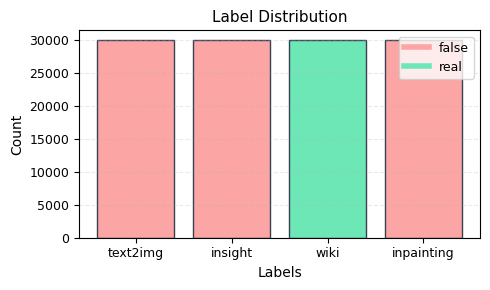

In [6]:
plot_binary_label_distribution(df)

In [7]:
df.head()

,image,label
0,images/text2img/61/19242061_1982-08-16_2009.jpg,text2img
1,images/text2img/61/2399661_1977-09-02_2008.jpg,text2img
2,images/text2img/61/41899761_1989-10-06_2012.jpg,text2img
3,images/text2img/61/15330561_1943-08-11_2002.jpg,text2img
4,images/text2img/61/2075561_1966-06-14_2010.jpg,text2img


In [8]:
# change label names to numbers
# wiki = 1 else = 0
#df['label'] = df['label'].apply(lambda x: 1 if x == 'wiki' else 0)
#label_counts = df["label"].value_counts()
#print(label_counts)d

# Experimental Dataset 
Sampling n Images per Class for parameter tuning

In [9]:
n = 400  # per class
# Select 500 random samples from 'wiki' label
wiki_sample = df[df["label"] == "wiki"].sample(n=n, random_state=42) 
# Select 500 random samples from the combined 'text2img', 'insight', and 'inpainting' labels
fake_sample = df[df["label"].isin(["text2img", "insight", "inpainting"])].sample(n=n, random_state=42)
exp_df = pd.concat([wiki_sample, fake_sample]).reset_index(drop=True)


In [10]:
label_counts = exp_df["label"].value_counts()
print(label_counts)

label
wiki          400
insight       140
text2img      138
inpainting    122
Name: count, dtype: int64


In [11]:
# map lables to real or fake

def map_labels(label):
    if label == "wiki":
        return 1
    else:
        return 0

exp_df['label'] = exp_df['label'].apply(map_labels)

In [12]:
label_counts = exp_df["label"].value_counts()
print(label_counts)

label
1    400
0    400
Name: count, dtype: int64


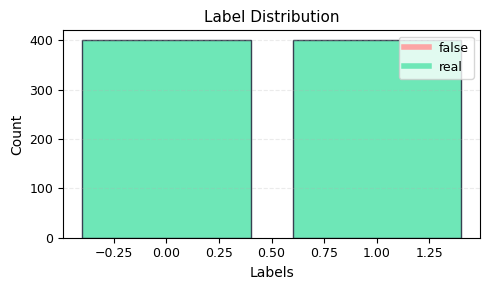

In [13]:
plot_binary_label_distribution(exp_df)

In [14]:
exp_df.head()
exp_df.tail()

,image,label
795,images/insight/49/2101649_1958-08-20_2014.jpg,0
796,images/text2img/57/22349257_1967-08-22_2011.jpg,0
797,images/inpainting/54/370654_1935-12-23_1976.jpg,0
798,images/inpainting/41/1649341_1951-04-13_2007.jpg,0
799,images/text2img/42/45451842_1991-08-26_2012.jpg,0


In [15]:
def show_img(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

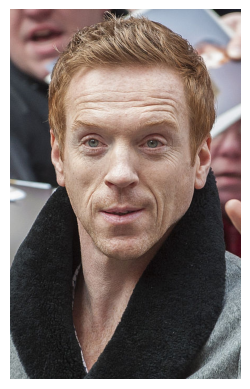

In [16]:
show_img(exp_df[exp_df["label"] == 1].sample(n=1, random_state=42)["image"].values[0]) # show a random image with label 1

# Image Preprocessing
what we ll first do:

- Resize the images to a fixed size (224x224 pixels), but HOW?
    - can these transformation be a problem, once we are "manipulating them" check this. Maybe instead of recising, we can use a crop(that keep the naturality of the image)

- Normalize the pixel values to be between 0 and 1?

- check what kind of normalization is our model prepared for...


"Finally the values are first rescaled to [0.0, 1.0] and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]." from: https://pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html

In [17]:
'''
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  #couse torch models work with tensors
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # this model was trainned on ImageNet where the images have that mean and std -> chekc if the model really need normalized input: if don't then leave it like that.
])
'''

"\ntransform = transforms.Compose([\n    transforms.Resize((224, 224)),\n    transforms.ToTensor(),  #couse torch models work with tensors\n    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # this model was trainned on ImageNet where the images have that mean and std -> chekc if the model really need normalized input: if don't then leave it like that.\n])\n"

In [18]:
transform = transforms.Compose([
    #transforms.Resize(256, interpolation=transforms.InterpolationMode.BILINEAR),#  do not recise
    transforms.CenterCrop(224),
    transforms.ToTensor(),  # Converts to [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [19]:
# Function to display image after transformation
def show_transformed_img(img_path, transform):
    img = Image.open(img_path)
    img_transformed = transform(img)

    # Convert the transformed image back to displayable format
    img_transformed = img_transformed.permute(1, 2, 0).numpy()  # Change shape to (H, W, C)
    img_transformed = (img_transformed * 0.5) + 0.5  # Unnormalize
    img_transformed = img_transformed.clip(0, 1)  # Ensure values are between 0 and 1

    plt.imshow(img_transformed)
    plt.axis('off')
    plt.show()

Original Image: images/wiki/17/2795917_1959-10-16_2013.jpg


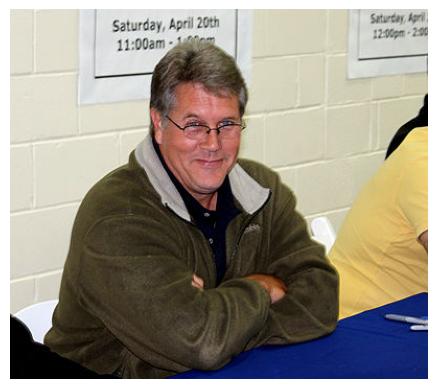

Transformed Image:


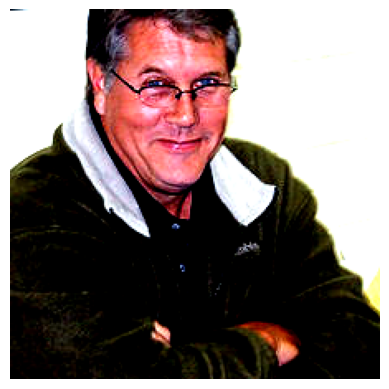

Original Image: images/wiki/02/13821502_1987-11-14_2008.jpg


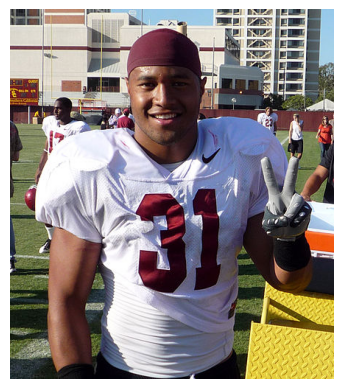

Transformed Image:


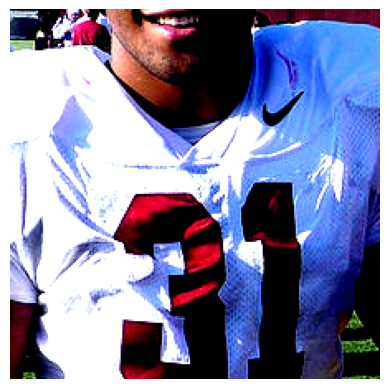

Original Image: images/insight/77/1176977_1930-01-28_2015.jpg


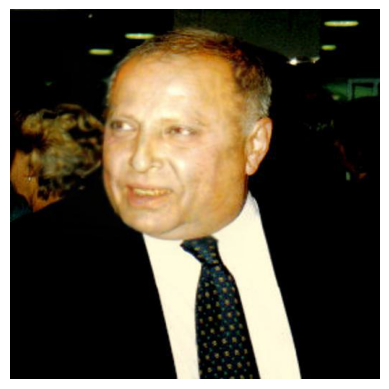

Transformed Image:


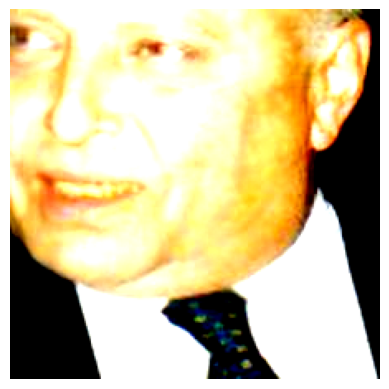

In [20]:
# Select 3 image paths from the dataset
sample_images = df["image"].sample(3, random_state=42).tolist()

# Show original and transformed images
for img_path in sample_images:
    print(f"Original Image: {img_path}")
    show_img(img_path)
    print("Transformed Image:")
    show_transformed_img(img_path, transform)

# Testing Pre-Trained Model

Checking mps availability (for macos)

In [21]:
# Check that MPS is available
if not torch.backends.mps.is_available():
    if not torch.backends.mps.is_built():
        print("MPS not available because the current PyTorch install was not "
              "built with MPS enabled.")
    else:
        print("MPS not available because the current MacOS version is not 12.3+ "
              "and/or you do not have an MPS-enabled device on this machine.")

else:
    print("MPS is available and enabled.")
    mps_device = torch.device("mps")

MPS is available and enabled.


### Loading a Pretrained Vision Transformer

vit_b_16 is a Vision Transformer (ViT) model from the torchvision library, specifically:
- ViT-B/16 → Base (B) model with 16x16 patch size
- Pretrained on ImageNet-1k (1.3M images, 1,000 classes)
- Available in torchvision.models.vision_transformer. It is the Torchvision equivalent of Hugging Face’s google/vit-base-patch16-224.

This model has 86,567,656. we can consider it a light model.

In [22]:
# Load pretrained ViT from Torchvision
model = vit_b_16(pretrained=True)   # try a non-pretrained one -> model = vit_b_16(weights=None) or set wheits to a normal distribution
model.eval()  # Set to evaluation mode
model.to(mps_device)

/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [23]:
#Calculate number of parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
#rint(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 86,567,656


In [24]:
# Function to preprocess and predict an image
def predict_image_torchvision(image_path):
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(mps_device)

    with torch.no_grad():
        outputs = model(image)   # here we're calling the model
        probs = torch.nn.functional.softmax(outputs, dim=-1)

    predicted_class = torch.argmax(probs, dim=-1).item()
    confidence = probs[0][predicted_class].item()

    return predicted_class, confidence

https://deeplearning.cms.waikato.ac.nz/user-guide/class-maps/IMAGENET/  

In this link u can find the imagenet classes and their corresponding labels and see how its predicting quite well.

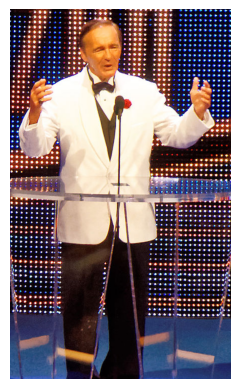

In [25]:
sample_image_path = exp_df.iloc[0]["image"]
show_img(sample_image_path)

In [26]:
predict_image_torchvision(sample_image_path)

(617, 0.9200506806373596)

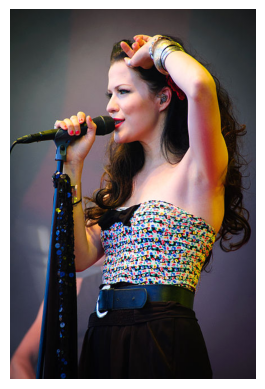

In [27]:
sample_image_path = exp_df.iloc[2]["image"]
show_img(sample_image_path)

In [28]:
predict_image_torchvision(sample_image_path)

(585, 0.17142519354820251)

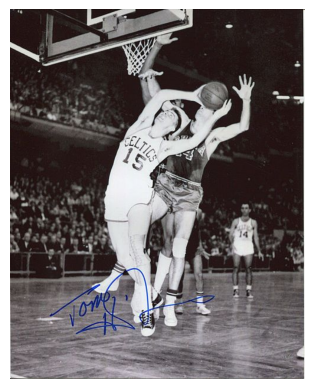

In [29]:
sample_image_path = exp_df.iloc[60]["image"]
show_img(sample_image_path)

In [30]:
predict_image_torchvision(sample_image_path)   

(981, 0.300287663936615)

# Trainning

So... the ViT is pre-trained only on natural images and it's pretrained for a 1000 classes classification problem (and performs really well for those 1000).  But how ca we make this model to predict our 2 classes (real and fake) ? And train it on our dataset?
like this:

- Remove the last classification layer.
- Replace it with a new fully connected layer (nn.Linear) for binary classification. with 2 outputs.
- Fine-tune the model on real vs. deepfake images. maybe a LoRA maybe not

https://github.com/NielsRogge/Transformers-Tutorials/tree/master/VisionTransformer

1. **Curstom Pytorch Dataset**

In [31]:
class ImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df  # Store the DataFrame
        self.transform = transform  # Store transformations

    def __len__(self):
        return len(self.df)  # Return dataset size

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image"]  # Get image according to the path
        label = torch.tensor(self.df.iloc[idx]["label"], dtype=torch.long)  # Directly use stored label

        image = Image.open(img_path).convert("RGB")  # NOT KNOW IF NEED TO CONVERT TO RGB...

        if self.transform:
            image = self.transform(image)  # Apply transformations

        return image, label  # Return (image, label) tuple
    
exp_ds = ImageDataset(exp_df, transform=transform)

2. **Output head (change it for 2)**

- 2.1 **Smot Change**

In [32]:
# Get the input feature size from the existing head
#num_ftrs = model.heads.head.in_features  # typically 768
# Replace the head with a sequential block containing an intermediate layer
#model.heads.head = nn.Sequential(
#    nn.Linear(num_ftrs, 256),  # Intermediate layer reducing dimension gradually
#    nn.ReLU(),                 # Non-linear activation
#    nn.Linear(256, 2)          # Final layer for binary classification (real vs. fake)
#)

#model.to(mps_device)

- 2.2 **Abrupt Change**

In [33]:
# Modify the classifier head to predict only 2 classes (real vs. fake)
#num_ftrs = model.heads.head.in_features  # Get input features of the last layer
#model.heads.head = nn.Linear(num_ftrs, 2)  # Replace with a new linear layer for binary classification
#model.to(mps_device)  # Move the model to the MPS device

### Trainning Fucntions

Trainning Parameters

In [34]:
# Define KFold cross-validator (e.g., 5-fold)
#kf = KFold(n_splits=3, shuffle=True, random_state=42)
# Define StratifiedKFold cross-validator
#SFK
# Extract labels from the dataset for stratified splitting
labels = np.array([exp_ds[i][1].item() for i in range(len(exp_ds))])
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42) # for stratified sampling that means that the distribution of the labels is the same in each fold



# Parameters for training
num_epochs = 15  # adjust as needed
batch_size = 32
learning_rate = 0.0001


In [ ]:
# Store metrics from each fold
fold_metrics = {}
training_losses_per_folder = {}
training_accuracies_per_folder = {}
validation_losses_per_folder = {}
validation_accuracies_per_folder = {}

for fold, (train_idx, val_idx) in enumerate(skf.split(np.arange(len(exp_ds)), labels)):
    print(f"\nStarting Fold {fold+1}")

    # Create subsets for the current fold
    train_subset = Subset(exp_ds, train_idx)
    val_subset = Subset(exp_ds, val_idx)
    
    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
    
    # Initialize the model for this fold
    model = vit_b_16(pretrained=True)


    num_ftrs = model.heads.head.in_features  # typically 768
    #Replace the head with a sequential block containing an intermediate layer
    model.heads.head = nn.Sequential(
        nn.Linear(num_ftrs, 256),  # Intermediate layer reducing dimension gradually
        nn.ReLU(),                 # Non-linear activation
        nn.Linear(256, 2)          # Final layer for binary classification (real vs. fake)
    )

    model.to(mps_device)

    # Freeze the entire backbone
    #for param in model.parameters():
    #    param.requires_grad = False
    
    # Replace the classifier head with a new zero-initialized layer for 2 classes
    #in_features = model.heads.head.in_features
    #model.heads.head = nn.Linear(in_features, 2)
    #
    ## Zero-initialize the classifier head weights and biases
    #nn.init.zeros_(model.heads.head.weight)
    #nn.init.zeros_(model.heads.head.bias)
#
    ## Unfreeze the classifier head parameters so they can be trained
    #for param in model.heads.head.parameters():
    #    param.requires_grad = True
    #
    #model.to(mps_device)  # Move model to device
    
    
    # Modify the classifier head to output 2 classes (binary classification)
    #in_features = model.heads.head.in_features
    #model.heads.head = nn.Linear(in_features, 2)
    #model.to(mps_device)  # move model to MPS device (or CPU/GPU as available)
    
    # Define loss function and optimizer
    criterion = nn.CrossEntropyLoss()  # think it's the better one
    # optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    #optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    # Define loss function and optimizer (only updates unfrozen parameters)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                            lr=learning_rate, weight_decay=1e-4)
    

    # Initialize lists to store metrics for this fold
    training_losses_per_folder[fold] = []
    training_accuracies_per_folder[fold] = []
    validation_losses_per_folder[fold] = []
    validation_accuracies_per_folder[fold] = []

    
    # Training loop for the current fold
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        


        for images, labels in train_loader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            #with torch.autograd.detect_anomaly():
            #    loss.backward() # for error detection
            loss.backward()
            # clipping gradinets to avoid Nan values
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Add gradient clipping to avoid Nan loss values
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
        
        train_loss = running_loss / total
        train_acc = correct / total

        # Store training metrics for this epoch
        training_losses_per_folder[fold].append(train_loss)
        training_accuracies_per_folder[fold].append(train_acc)
        
        # Evaluation on validation set
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(mps_device), labels.to(mps_device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                preds = torch.argmax(outputs, dim=1)
                correct_val += (preds == labels).sum().item()
                total_val += labels.size(0)
        
        val_loss /= total_val
        val_acc = correct_val / total_val

        # Store validation metrics for this epoch
        validation_losses_per_folder[fold].append(val_loss)
        validation_accuracies_per_folder[fold].append(val_acc)
        
        print(f"Fold {fold+1} | Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    
    # Store the validation accuracy for this fold
    fold_metrics[fold] = val_acc

# After all folds, you can compute average performance
avg_val_acc = sum(fold_metrics.values()) / len(fold_metrics)
print(f"\nAverage Validation Accuracy over {skf.get_n_splits()} folds: {avg_val_acc:.4f}")


Starting Fold 1


/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Fold 1 | Epoch 1/15 | Train Loss: 0.5420, Train Acc: 0.7092 | Val Loss: 0.2435, Val Acc: 0.9176
Fold 1 | Epoch 2/15 | Train Loss: 0.1748, Train Acc: 0.9437 | Val Loss: 0.2380, Val Acc: 0.8951
Fold 1 | Epoch 3/15 | Train Loss: 0.1372, Train Acc: 0.9493 | Val Loss: 0.6270, Val Acc: 0.8315
Fold 1 | Epoch 4/15 | Train Loss: 0.1531, Train Acc: 0.9493 | Val Loss: 0.4206, Val Acc: 0.8727
Fold 1 | Epoch 5/15 | Train Loss: 0.1152, Train Acc: 0.9662 | Val Loss: 0.3446, Val Acc: 0.9064
Fold 1 | Epoch 6/15 | Train Loss: 0.0662, Train Acc: 0.9756 | Val Loss: 0.4217, Val Acc: 0.9176
Fold 1 | Epoch 7/15 | Train Loss: 0.0203, Train Acc: 0.9944 | Val Loss: 0.4060, Val Acc: 0.9101
Fold 1 | Epoch 8/15 | Train Loss: 0.0050, Train Acc: 0.9981 | Val Loss: 0.3724, Val Acc: 0.9288
Fold 1 | Epoch 9/15 | Train Loss: 0.0110, Train Acc: 0.9962 | Val Loss: 0.8183, Val Acc: 0.8614
Fold 1 | Epoch 10/15 | Train Loss: 0.0607, Train Acc: 0.9850 | Val Loss: 0.6001, Val Acc: 0.8876
Fold 1 | Epoch 11/15 | Train Loss: 0.02

In [59]:
print(fold_metrics)

{0: 0.8352059925093633, 1: 0.8052434456928839, 2: 0.8533834586466166}


In [60]:
print("training_losses: ", training_losses_per_folder)

training_losses:  {0: [0.6315031609660465, 0.4765353065829787, 0.4045398595968286, 0.35417739060090586, 0.3180537465924841, 0.2889429681967615, 0.2641119415719782, 0.2455102996463847, 0.22565563059434657, 0.21155351417149657, 0.19678860712677632, 0.18689775047561688, 0.17474042351652935, 0.16494197631866356, 0.15574430689690932], 1: [0.6116293641908084, 0.46156082066094, 0.38732393569615275, 0.3422567524561068, 0.3057247363380375, 0.2748362172052516, 0.25026962387517065, 0.22878244986118115, 0.2122974441042537, 0.19626461215471014, 0.18384075318559248, 0.1706083369411626, 0.1598951254340542, 0.15139900762972197, 0.1427943848255204], 2: [0.6194728429844317, 0.4683331434199873, 0.39760458781924585, 0.3510172143857577, 0.31541810120536146, 0.2874631289015995, 0.2655388309379642, 0.24759878117716713, 0.22831360979026624, 0.21488626396164912, 0.2011025387249636, 0.19009729991021673, 0.17964694294590183, 0.16779250805074356, 0.16034694853123654]}


In [61]:
print("trainning_accurecies: ", training_accuracies_per_folder)

trainning_accurecies:  {0: [0.6566604127579737, 0.8311444652908068, 0.849906191369606, 0.8911819887429644, 0.9099437148217636, 0.9136960600375235, 0.9287054409005628, 0.9305816135084428, 0.9437148217636022, 0.9512195121951219, 0.9587242026266416, 0.9587242026266416, 0.9699812382739212, 0.9681050656660413, 0.975609756097561], 1: [0.6791744840525328, 0.8030018761726079, 0.8405253283302064, 0.874296435272045, 0.9099437148217636, 0.9287054409005628, 0.9399624765478424, 0.9568480300187617, 0.9643527204502814, 0.9737335834896811, 0.9737335834896811, 0.975609756097561, 0.9812382739212008, 0.9831144465290806, 0.9849906191369606], 2: [0.6573033707865169, 0.8202247191011236, 0.8558052434456929, 0.8838951310861424, 0.9082397003745318, 0.9232209737827716, 0.9325842696629213, 0.9325842696629213, 0.947565543071161, 0.9531835205992509, 0.9606741573033708, 0.9662921348314607, 0.9625468164794008, 0.9681647940074907, 0.9681647940074907]}


In [62]:
print("validation_losses:", validation_losses_per_folder)

validation_losses: {0: [0.5297579466180409, 0.47028385443187387, 0.4384549524676934, 0.4200568355424574, 0.41089072254266634, 0.40651177344250766, 0.390102164798908, 0.39787064900112507, 0.38669852594311316, 0.388733446598053, 0.39410734171054784, 0.39155518701683717, 0.38878673755944, 0.3944665197464411, 0.394560081570336], 1: [0.5461601583698715, 0.4838865556743708, 0.44591572936554524, 0.42557619975300764, 0.41105424487188963, 0.4001593142189783, 0.39582814326447047, 0.38641747698355255, 0.3899075939190968, 0.38135204120968164, 0.378446816616737, 0.3840485278810008, 0.3850951111048795, 0.38642437951395125, 0.3852512307381362], 2: [0.5340999877990636, 0.4706444758221619, 0.43609154089949187, 0.41334256384157597, 0.39726645269788297, 0.38915702991915824, 0.38315961750826444, 0.37324611652166323, 0.3728904734204586, 0.36908925957697675, 0.36502664228131, 0.36239846196389736, 0.36435365867345854, 0.36325085107097055, 0.3683991702203464]}


In [63]:
print("validation_accuracies:", validation_accuracies_per_folder)

validation_accuracies: {0: [0.797752808988764, 0.8014981273408239, 0.8202247191011236, 0.8164794007490637, 0.8239700374531835, 0.8239700374531835, 0.8239700374531835, 0.8426966292134831, 0.846441947565543, 0.850187265917603, 0.846441947565543, 0.8389513108614233, 0.8389513108614233, 0.8426966292134831, 0.8352059925093633], 1: [0.7453183520599251, 0.7940074906367042, 0.8202247191011236, 0.8277153558052435, 0.8314606741573034, 0.8277153558052435, 0.8314606741573034, 0.8352059925093633, 0.8164794007490637, 0.8277153558052435, 0.8277153558052435, 0.8277153558052435, 0.8277153558052435, 0.8164794007490637, 0.8052434456928839], 2: [0.7631578947368421, 0.7969924812030075, 0.8157894736842105, 0.8421052631578947, 0.8308270676691729, 0.8383458646616542, 0.8646616541353384, 0.8571428571428571, 0.849624060150376, 0.8533834586466166, 0.8571428571428571, 0.8571428571428571, 0.8533834586466166, 0.8458646616541353, 0.8533834586466166]}


save into a dataframe and save it as a csv

In [ ]:
data = {
    'mean': fold_metrics,
    'train_loss': training_losses_per_folder,
    'train_acc': training_accuracies_per_folder,
    'val_loss': validation_losses_per_folder,
    'val_acc': validation_accuracies_per_folder,
    'descipttion': 'full; stratified kfold; no recize; center crop; specific normalizatoin; num_epochs = 15 batch_size = 32, learning_rate = 0.001; learning rate FIXED BUT 0.001; criterion = nn.CrossEntropyLoss(), optimizer = optim.AdamW(model.parameters(), weight decay, lr=learning_rate)',
    'time': '26 mins, 08 segundos'
}


In [82]:
data = pd.DataFrame(data)

In [83]:
data

,mean,train_loss,train_acc,val_loss,val_acc,descipttion,time
0,0.835206,"[0.6315031609660465, 0.4765353065829787, 0.404...","[0.6566604127579737, 0.8311444652908068, 0.849...","[0.5297579466180409, 0.47028385443187387, 0.43...","[0.797752808988764, 0.8014981273408239, 0.8202...",freeze backboen peft_classification_head_train...,"26 mins, 08 segundos"
1,0.805243,"[0.6116293641908084, 0.46156082066094, 0.38732...","[0.6791744840525328, 0.8030018761726079, 0.840...","[0.5461601583698715, 0.4838865556743708, 0.445...","[0.7453183520599251, 0.7940074906367042, 0.820...",freeze backboen peft_classification_head_train...,"26 mins, 08 segundos"
2,0.853383,"[0.6194728429844317, 0.4683331434199873, 0.397...","[0.6573033707865169, 0.8202247191011236, 0.855...","[0.5340999877990636, 0.4706444758221619, 0.436...","[0.7631578947368421, 0.7969924812030075, 0.815...",freeze backboen peft_classification_head_train...,"26 mins, 08 segundos"


In [ ]:
data.to_csv('results/train_2.csv', index=False)

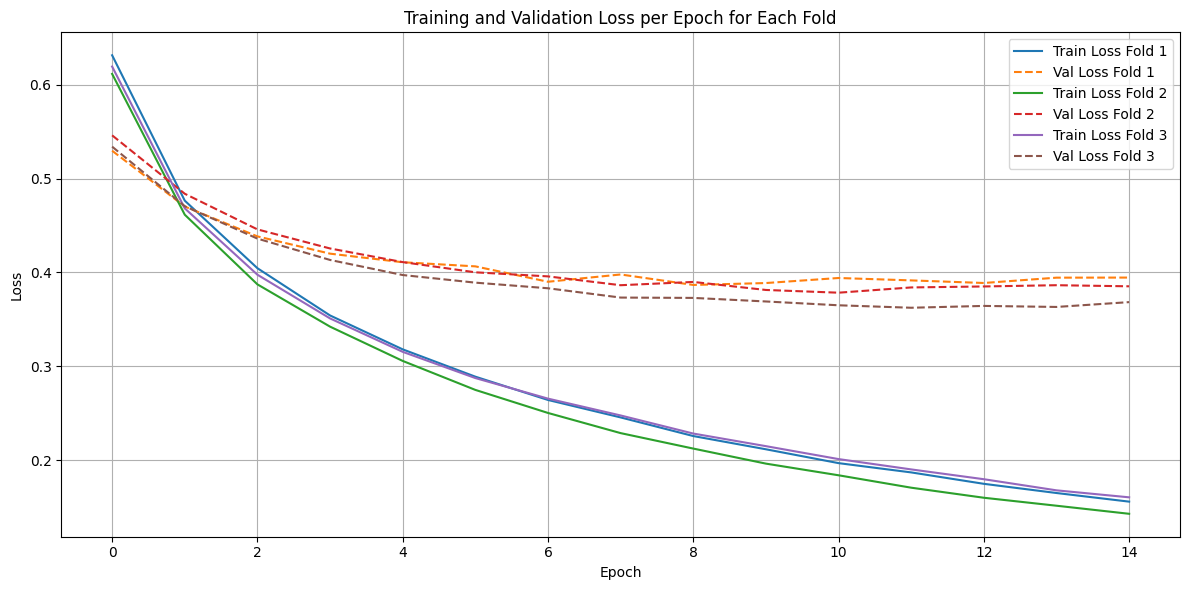

In [85]:
# Plot training and validation loss for each fold
plt.figure(figsize=(12, 6))
for fold in training_losses_per_folder:
    plt.plot(training_losses_per_folder[fold], label=f"Train Loss Fold {fold+1}")
    plt.plot(validation_losses_per_folder[fold], linestyle='--', label=f"Val Loss Fold {fold+1}")
plt.title("Training and Validation Loss per Epoch for Each Fold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()